## 1)	Dataset exploration ##

In [1]:
import pandas as pd

# Load the three datasets
proteins = pd.read_csv("proteins_npx_raw.csv")
metadata = pd.read_csv("sample_metadata.csv")
annotation = pd.read_csv("protein_annotation.csv")

## a.	Amount of samples and features needs to be determined ##

In [5]:
# 1. Dataset dimensions
print("=== DATASET OVERVIEW ===")
print("Number of samples:", proteins.shape[0])
print("Number of proteins:", proteins.shape[1] - 1)
print("Number of metadata variables:", metadata.shape[1] - 1)
print("Number of annotated proteins:", annotation.shape[0])

# 2. Donor information
samples_per_donor = metadata["subject.subjectGuid"].value_counts()

print("\n=== DONOR INFORMATION ===")
print("Number of unique donors:", samples_per_donor.size)
print("Mean samples per donor:", round(samples_per_donor.mean(), 2))
print("Median samples per donor:", samples_per_donor.median())
print("Minimum samples per donor:", samples_per_donor.min())
print("Maximum samples per donor:", samples_per_donor.max())

# 3. Dataset consistency checks
print("\n=== DATASET CONSISTENCY ===")

print("Same sample IDs in NPX and metadata:",
      set(proteins["sample_kit_id"]) ==
      set(metadata["sample_kit_id"]))

print("Same sample order:",
      proteins["sample_kit_id"].equals(
          metadata["sample_kit_id"]
      ))

print("All proteins present in annotation:",
      set(proteins.columns[1:]).issubset(
          set(annotation["protein"])
      ))


=== DATASET OVERVIEW ===
Number of samples: 867
Number of proteins: 1481
Number of metadata variables: 75
Number of annotated proteins: 1481

=== DONOR INFORMATION ===
Number of unique donors: 96
Mean samples per donor: 9.03
Median samples per donor: 10.0
Minimum samples per donor: 1
Maximum samples per donor: 10

=== DATASET CONSISTENCY ===
Same sample IDs in NPX and metadata: True
Same sample order: True
All proteins present in annotation: True


**Dataset exploration – Dataset structure**

The dataset consists of 867 plasma samples collected from 96 unique donors, with a median of 10 samples per donor (range: 1–10). The protein expression dataset contains normalized protein expression (NPX) values for 1,481 proteins. In addition, sample metadata include 75 variables and one sample identifier, while protein annotation information is available for all 1,481 proteins.

Sample identifiers were consistent between the protein expression and metadata datasets, and all protein names were represented in the annotation dataset. The presence of multiple samples per donor indicates a longitudinal study design, which should be considered in subsequent statistical analyses.

## b.	Identify type of variables ##

In [12]:
# Count Python data types in each dataset
print("=== PROTEIN EXPRESSION ===")
print(proteins.dtypes.value_counts())

print("\n=== SAMPLE METADATA ===")
print(metadata.dtypes.value_counts())

print("\n=== PROTEIN ANNOTATION ===")
print(annotation.dtypes.value_counts())

=== PROTEIN EXPRESSION ===
float64    1481
str           1
Name: count, dtype: int64

=== SAMPLE METADATA ===
float64    54
str        16
int64       6
Name: count, dtype: int64

=== PROTEIN ANNOTATION ===
str        6
float64    4
int64      1
bool       1
Name: count, dtype: int64


In [11]:
# Create an overview of all metadata variables
variable_types = pd.DataFrame({
    "Python datatype": metadata.dtypes.astype(str),
    "Missing (%)": (metadata.isna().mean() * 100).round(1)
})

# Display all variables
with pd.option_context("display.max_rows", None):
    display(variable_types)

,Python datatype,Missing (%)
sample_kit_id,str,0.0
subject.subjectGuid,str,0.0
cohort.cohortGuid,str,0.0
subject.biologicalSex,str,0.0
subject.ageGroup,str,0.0
sample.subjectAgeAtDraw,int64,0.0
sample.visitName,str,0.0
sample.daysSinceFirstVisit,int64,0.0
cmv_status,str,0.0
olink_plate_id,str,0.0


In [13]:
# Statistical classification of relevant variables
statistical_types = {
    "infl.hs_crp": "Continuous",
    "subject.ageGroup": "Ordinal (Young/Older Adult)",
    "sample.subjectAgeAtDraw": "Quantitative (age in years)",
    "subject.biologicalSex": "Nominal",
    "cmv_status": "Nominal",
    "am.bmi": "Continuous",
    "olink_batch_id": "Nominal (technical)",
    "sample.visitName": "Nominal",
    "subject.subjectGuid": "Nominal (identifier)"
}

# Create a summary table
variables_summary = pd.DataFrame({
    "Statistical type": statistical_types,
    "Python datatype": metadata[
        list(statistical_types)
    ].dtypes.astype(str),
    "Missing (%)": (
        metadata[list(statistical_types)]
        .isna().mean() * 100
    ).round(1)
})

display(variables_summary)


,Statistical type,Python datatype,Missing (%)
infl.hs_crp,Continuous,float64,1.8
subject.ageGroup,Ordinal (Young/Older Adult),str,0.0
sample.subjectAgeAtDraw,Quantitative (age in years),int64,0.0
subject.biologicalSex,Nominal,str,0.0
cmv_status,Nominal,str,0.0
am.bmi,Continuous,float64,21.3
olink_batch_id,Nominal (technical),str,0.0
sample.visitName,Nominal,str,0.0
subject.subjectGuid,Nominal (identifier),str,0.0


**Variable type identification**

Variable types were inspected using the Pandas `dtypes` attribute. The protein expression dataset contained 1,481 numerical NPX features (`float64`) and one sample identifier (`str`). The sample metadata consisted of 54 floating-point, 6 integer and 16 string variables. The protein annotation dataset contained 4 floating-point, 1 integer, 6 string and 1 Boolean variable.

Variables were additionally classified according to their statistical measurement type. Protein expression and hs-CRP were treated as continuous variables, while biological sex and Olink batch were classified as nominal variables. The predefined age groups (Young Adult and Older Adult) were classified as ordinal. Donor and sample identifiers were used exclusively for identification and data linkage.


Additionally, the percentage of missing values was calculated for each metadata variable to provide an initial overview of data completeness.

Relevant variables were classified according to their statistical measurement type (nominal, ordinal, discrete or continuous). This classification was based on the biological meaning of the variables rather than solely on their Python data type.

The percentage of missing values was included as a descriptive quality indicator. Decisions regarding missing-value handling will be addressed separately during data preprocessing.

## c.	Check if there are doubles for samples/subjects + are there repeated measures for donors ##

In [9]:
print("=== DUPLICATE SAMPLE IDs ===")

print("Duplicates in protein expression:",
      proteins["sample_kit_id"].duplicated().sum())

print("Duplicates in metadata:",
      metadata["sample_kit_id"].duplicated().sum())

print("\n=== REPEATED MEASUREMENTS ===")

samples_per_donor = metadata.groupby(
    "subject.subjectGuid"
)["sample_kit_id"].nunique()

print("Donors with one sample:",
      (samples_per_donor == 1).sum())

print("Donors with multiple samples:",
      (samples_per_donor > 1).sum())

print("\nDistribution of samples per donor:")
display(samples_per_donor.value_counts().sort_index())


=== DUPLICATE SAMPLE IDs ===
Duplicates in protein expression: 0
Duplicates in metadata: 0

=== REPEATED MEASUREMENTS ===
Donors with one sample: 1
Donors with multiple samples: 95

Distribution of samples per donor:


sample_kit_id
1      1
2      4
3      3
4      1
5      1
6      3
8      2
9      4
10    77
Name: count, dtype: int64

In [14]:
# Select one observation per donor
donors = metadata.drop_duplicates(
    subset="subject.subjectGuid"
)

# Count donors by age group, sex and CMV status
donor_distribution = pd.crosstab(
    donors["subject.ageGroup"],
    [
        donors["subject.biologicalSex"],
        donors["cmv_status"]
    ],
    margins=True
)

print("=== DONOR DISTRIBUTION ===")
display(donor_distribution)

=== DONOR DISTRIBUTION ===


subject.biologicalSex   Female              Male          All
cmv_status            Negative Positive Negative Positive    
subject.ageGroup                                             
Older Adult                 10       17       12        8  47
Young Adult                 18       10       12        9  49
All                         28       27       24       17  96

In [33]:
# Check consistency of donor-level variables
donor_variables = [
    "subject.ageGroup",
    "subject.biologicalSex",
    "cmv_status"
]

for variable in donor_variables:
    inconsistent = (
        metadata.groupby("subject.subjectGuid")[variable]
        .nunique(dropna=False)
        .gt(1)
        .sum()
    )
    print(f"{variable}: {inconsistent} inconsistent donors")


subject.ageGroup: 0 inconsistent donors
subject.biologicalSex: 0 inconsistent donors
cmv_status: 0 inconsistent donors


**Interpretation - Duplicates and repeated measurements**

No duplicate sample identifiers were detected in either the protein expression dataset or the sample metadata.

The dataset contains 867 samples originating from 96 unique donors. Of these, 95 donors contributed multiple samples, with 77 donors contributing 10 samples each. The median number of samples per donor was 10 (range: 1–10).

These findings confirm the presence of repeated measurements within donors. Since measurements from the same donor are not statistically independent, the longitudinal structure of the dataset should be considered in subsequent statistical analyses. No samples were removed at this stage.

**Donor distribution**

To avoid counting repeated measurements as independent observations, one record per donor was selected using the unique donor identifier.

The dataset contained 96 unique donors, including 49 Young Adults and 47 Older Adults. The age groups were approximately balanced in size. Among the 96 donors, 55 were female and 41 were male.

Donors were additionally stratified according to CMV serostatus, allowing an initial assessment of the distribution of potential biological confounders across age groups.

Although the dataset contains 867 samples, the number of unique donors is particularly important when evaluating independent biological replication and statistical power.

## d.	Identify relevant variables ##

In [10]:
relevant_variables = [
    "sample_kit_id",
    "subject.subjectGuid",
    "subject.ageGroup",
    "sample.subjectAgeAtDraw",
    "subject.biologicalSex",
    "infl.hs_crp",
    "olink_batch_id",
    "sample.visitName",
    "sample.daysSinceFirstVisit"
]

# Create a subset with relevant metadata
metadata_relevant = metadata[relevant_variables].copy()

# Inspect the new dataframe
print("=== RELEVANT METADATA ===")
print("Number of samples:", metadata_relevant.shape[0])
print("Number of variables:", metadata_relevant.shape[1])

display(metadata_relevant.head())


=== RELEVANT METADATA ===
Number of samples: 867
Number of variables: 9


,sample_kit_id,subject.subjectGuid,subject.ageGroup,sample.subjectAgeAtDraw,subject.biologicalSex,infl.hs_crp,olink_batch_id,sample.visitName,sample.daysSinceFirstVisit
0,KT00001,BR1001,Young Adult,32,Female,0.3,20201752,Flu Year 1 Day 0,0
1,KT00002,BR1002,Young Adult,28,Male,0.3,20201752,Flu Year 1 Day 0,0
2,KT00003,BR1003,Young Adult,30,Female,1.9,20201752,Flu Year 1 Day 0,0
3,KT00004,BR1004,Young Adult,30,Male,0.3,20201752,Flu Year 1 Day 0,0
4,KT00006,BR1005,Young Adult,27,Female,0.5,20201752,Flu Year 1 Day 0,0


**Identification of relevant variables**

Nine metadata variables were selected based on their relevance to the research question. Age group was selected as the primary variable representing age, while hs-CRP was selected as a marker of systemic inflammation. Protein expression levels are available separately in the NPX dataset.

Biological sex and Olink batch were retained as potential confounding variables. Sample identifiers, donor identifiers and visit information were included to enable data integration and account for repeated measurements.

The resulting subset contained 867 samples and 9 metadata variables. No samples were excluded, and the original datasets were preserved.

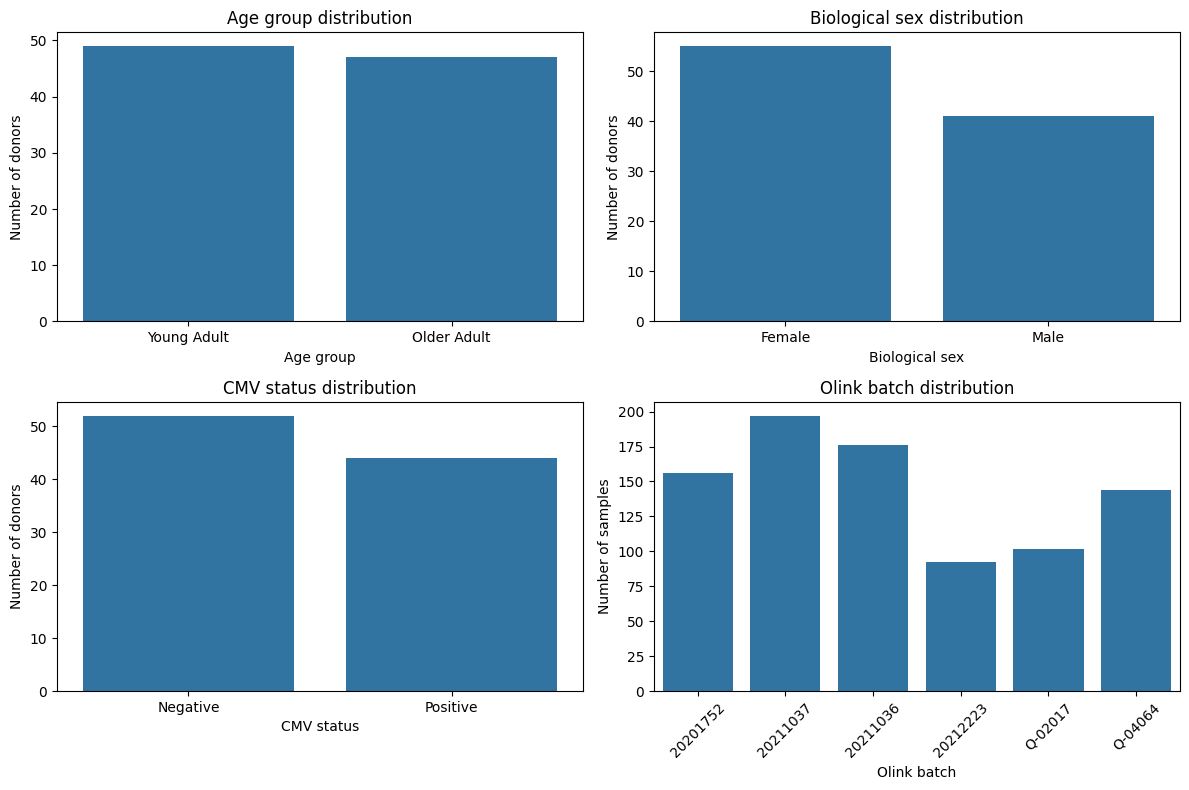

In [20]:
# === DISTRIBUTION OF CATEGORICAL VARIABLES ===

import matplotlib.pyplot as plt
import seaborn as sns

# Select one observation per donor
donors = metadata.drop_duplicates(
    subset="subject.subjectGuid"
)

# Create four barplots
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Age group (donor level)
sns.countplot(
    data=donors,
    x="subject.ageGroup",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Age group distribution")
axes[0, 0].set_ylabel("Number of donors")
axes[0, 0].set_xlabel("Age group")

# Biological sex (donor level)
sns.countplot(
    data=donors,
    x="subject.biologicalSex",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Biological sex distribution")
axes[0, 1].set_ylabel("Number of donors")
axes[0, 1].set_xlabel("Biological sex")

# CMV status (donor level)
sns.countplot(
    data=donors,
    x="cmv_status",
    ax=axes[1, 0]
)
axes[1, 0].set_title("CMV status distribution")
axes[1, 0].set_ylabel("Number of donors")
axes[1, 0].set_xlabel("CMV status")

# Olink batch (sample level)
sns.countplot(
    data=metadata,
    x="olink_batch_id",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Olink batch distribution")
axes[1, 1].set_ylabel("Number of samples")
axes[1, 1].set_xlabel("Olink batch")
axes[1, 1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


**Distribution of categorical variables**

The distributions of relevant categorical variables were visualized using barplots. Age group, biological sex and CMV status were examined at the donor level to avoid counting repeated measurements as independent individuals. Olink batch distribution was assessed at the sample level, since batch assignment is specific to individual samples.

These visualizations provide an overview of the study population and the distribution of technical factors. They may also help identify imbalances that should be considered when interpreting subsequent statistical analyses and potential outliers.

The study population consisted of 96 donors, including 49 Young Adults and 47 Older Adults, indicating a balanced distribution between age groups. There were slightly more female (n = 55) than male donors (n = 41). CMV status was also relatively balanced, with 52 CMV-negative and 44 CMV-positive donors.

The 867 samples were distributed across six Olink batches, with unequal batch sizes ranging from 92 to 197 samples. This variation in batch size is not necessarily a data quality issue, but potential batch-related effects should be investigated during subsequent quality control and statistical analyses.

## 3)	Outlier detection ##

## a. Checking distributions and visualizing outliers with boxplots ##

=== hs-CRP DESCRIPTIVE STATISTICS ===


count    851.000000
mean       1.411986
std        1.804367
min        0.300000
25%        0.400000
50%        0.700000
75%        1.600000
max       10.000000
Name: infl.hs_crp, dtype: float64

Missing values: 16


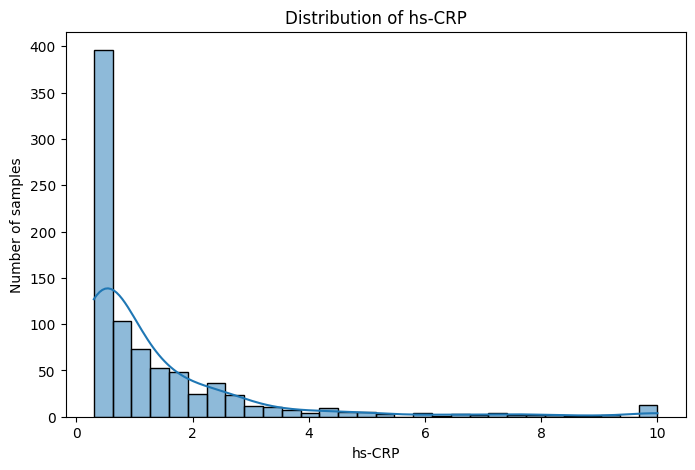

In [16]:
# === EXPLORATION OF hs-CRP DISTRIBUTION ===

import matplotlib.pyplot as plt
import seaborn as sns

# Select hs-CRP values
crp = metadata_relevant["infl.hs_crp"]

# Descriptive statistics
print("=== hs-CRP DESCRIPTIVE STATISTICS ===")
display(crp.describe())

print("Missing values:", crp.isna().sum())

# Histogram
plt.figure(figsize=(8, 5))

sns.histplot(
    crp.dropna(),
    bins=30,
    kde=True
)

plt.xlabel("hs-CRP")
plt.ylabel("Number of samples")
plt.title("Distribution of hs-CRP")

plt.show()


**Exploration of hs-CRP distribution**

The distribution of hs-CRP was examined using descriptive statistics and a histogram. Of the 867 samples, 851 had available hs-CRP measurements, while 16 values were missing (1.85%).

The distribution was strongly right-skewed, with most samples showing relatively low hs-CRP values and a smaller number exhibiting considerably higher values. This was reflected by a mean hs-CRP value of 1.41, which was substantially higher than the median of 0.70.

The observed hs-CRP values ranged from 0.3 to 10.0. The pronounced concentration of low values and the extended right tail suggest that further investigation of potential outliers is warranted.

However, elevated hs-CRP values may reflect genuine biological variation rather than technical errors. Therefore, no values were excluded at this stage.

=== hs-CRP OUTLIER DETECTION ===
Q1: 0.4
Q3: 1.6
IQR: 1.2
Lower bound: -1.4
Upper bound: 3.4
Number of potential outliers: 72
Percentage of valid measurements: 8.46


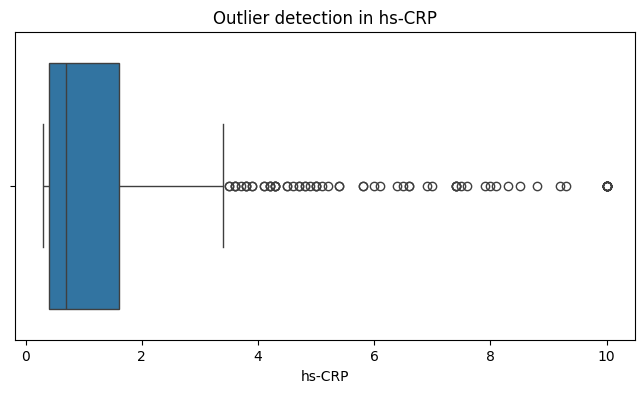

In [17]:
# === OUTLIER DETECTION: hs-CRP ===

# Calculate quartiles and IQR
Q1 = crp.quantile(0.25)
Q3 = crp.quantile(0.75)
IQR = Q3 - Q1

# Calculate outlier boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify potential outliers
outliers = crp[
    (crp < lower_bound) | (crp > upper_bound)
]

# Print results
print("=== hs-CRP OUTLIER DETECTION ===")
print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Lower bound:", round(lower_bound, 2))
print("Upper bound:", round(upper_bound, 2))
print("Number of potential outliers:", len(outliers))
print("Percentage of valid measurements:",
      round(len(outliers) / crp.notna().sum() * 100, 2))

# Visualize with a boxplot
plt.figure(figsize=(8, 4))

sns.boxplot(x=crp)

plt.xlabel("hs-CRP")
plt.title("Outlier detection in hs-CRP")

plt.show()


**Outlier detection in hs-CRP**

Potential outliers in hs-CRP concentrations were identified using the interquartile range (IQR) method, with outlier boundaries defined as Q1 − 1.5 × IQR and Q3 + 1.5 × IQR.

The lower and upper boundaries were −1.4 and 3.4, respectively. A total of 72 out of 851 available hs-CRP measurements (8.46%) were identified as potential outliers, all exceeding the upper boundary.

The relatively high number of upper outliers is consistent with the strongly right-skewed distribution of hs-CRP. Importantly, elevated hs-CRP concentrations may represent genuine biological variation related to systemic inflammation rather than technical measurement errors.

Therefore, no hs-CRP measurements were excluded at this stage. Further assessment of measurement limits and potential biological explanations may be considered before making final exclusion decisions.

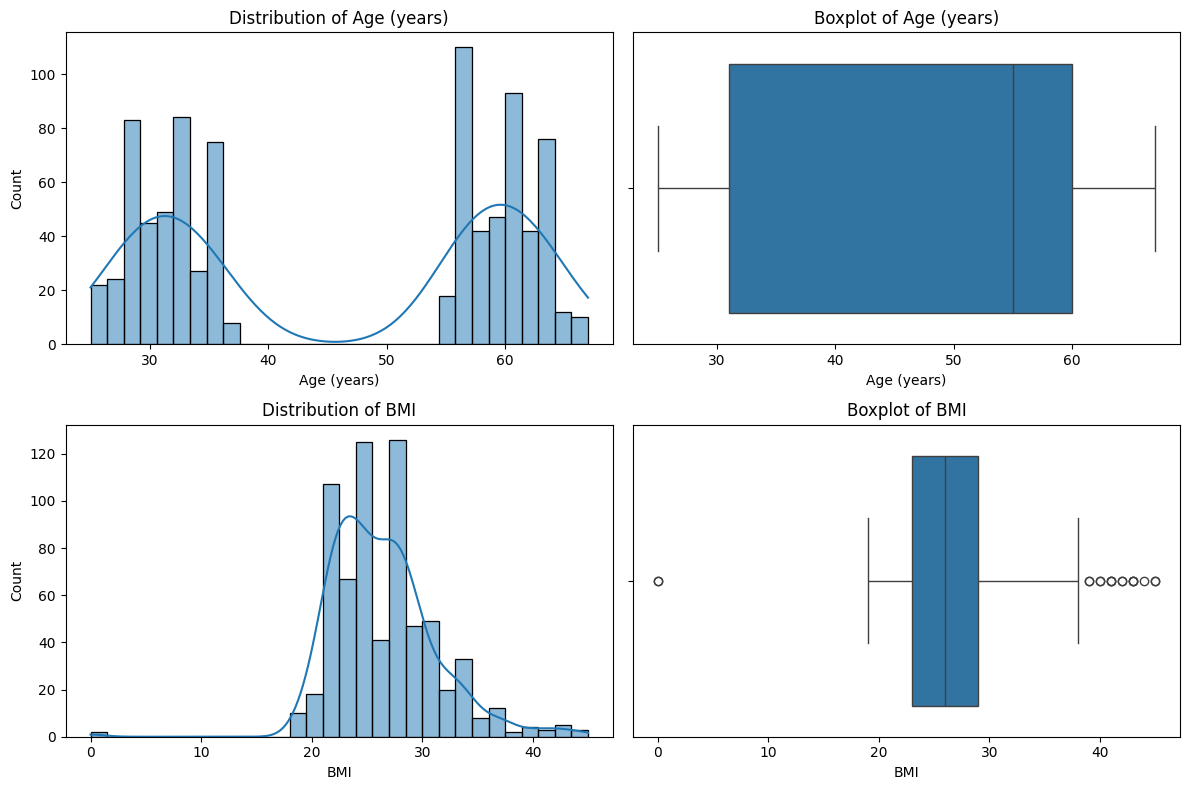

In [19]:
# === OUTLIER EXPLORATION: AGE AND BMI ===

import matplotlib.pyplot as plt
import seaborn as sns

variables = {
    "sample.subjectAgeAtDraw": "Age (years)",
    "am.bmi": "BMI"
}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for i, (variable, label) in enumerate(variables.items()):

    # Histogram
    sns.histplot(
        data=metadata,
        x=variable,
        bins=30,
        kde=True,
        ax=axes[i, 0]
    )

    axes[i, 0].set_title(f"Distribution of {label}")
    axes[i, 0].set_xlabel(label)

    # Boxplot
    sns.boxplot(
        data=metadata,
        x=variable,
        ax=axes[i, 1]
    )

    axes[i, 1].set_title(f"Boxplot of {label}")
    axes[i, 1].set_xlabel(label)

plt.tight_layout()
plt.show()


**Outlier exploration of age and BMI**

The distributions of age and BMI were examined using histograms and boxplots to identify potential outliers and assess the plausibility of the recorded values.

Age:

The age distribution was clearly bimodal, reflecting the two predefined age groups in the study population: Young Adults (25–37 years) and Older Adults (55–67 years). The absence of observations between 38 and 54 years is consistent with the study population structure rather than a data quality issue.

No potential age outliers were identified using the conventional 1.5 × IQR rule. Therefore, no age measurements were excluded or transformed. The predefined age-group variable was retained for subsequent analyses.

BMI:

The BMI distribution was approximately unimodal, with most measurements concentrated between 20 and 30 and a slight right-skew towards higher values. The boxplot identified potential outliers at both ends of the distribution, including an extremely low BMI value of 0 and several high BMI values above approximately 39.

A BMI of 0 is physiologically impossible and therefore suggests an invalid or incorrectly recorded measurement. In contrast, elevated BMI values may represent genuine biological variation and should not automatically be considered erroneous.

The invalid BMI measurement(s) should be treated as missing values during data cleaning, while the elevated BMI values should be retained unless further investigation reveals a technical or recording error. No observations were removed during this exploratory analysis.

In [21]:
# Check physiologically impossible BMI values
print("BMI values equal to zero:",
      (metadata["am.bmi"] == 0).sum())

print("BMI values below zero:",
      (metadata["am.bmi"] < 0).sum())

# Inspect samples with invalid BMI values
display(
    metadata.loc[
        metadata["am.bmi"] <= 0,
        ["sample_kit_id", "subject.subjectGuid",
         "am.bmi", "am.height", "am.weight"]
    ]
)


BMI values equal to zero: 2
BMI values below zero: 0


,sample_kit_id,subject.subjectGuid,am.bmi,am.height,am.weight
174,KT00380,BR1028,0.0,165.1,0.0
238,KT00544,BR1013,0.0,149.9,0.0


**Investigation of invalid BMI measurements**

Two samples (KT00380 and KT00544) were identified with a recorded BMI of 0. Both samples also had a recorded body weight of 0, despite having plausible height measurements.

Since a BMI and body weight of zero are physiologically impossible in living adults, these values were considered invalid and most likely represent missing or incorrectly recorded measurements.

Both samples will be retained in the dataset. The values will be replaced with `NaN` rather than removing the entire samples. This approach preserves valuable information, including protein expression and hs-CRP measurements, while preventing invalid values from influencing subsequent analyses. The handling of missing BMI values will be addressed during further preprocessing.

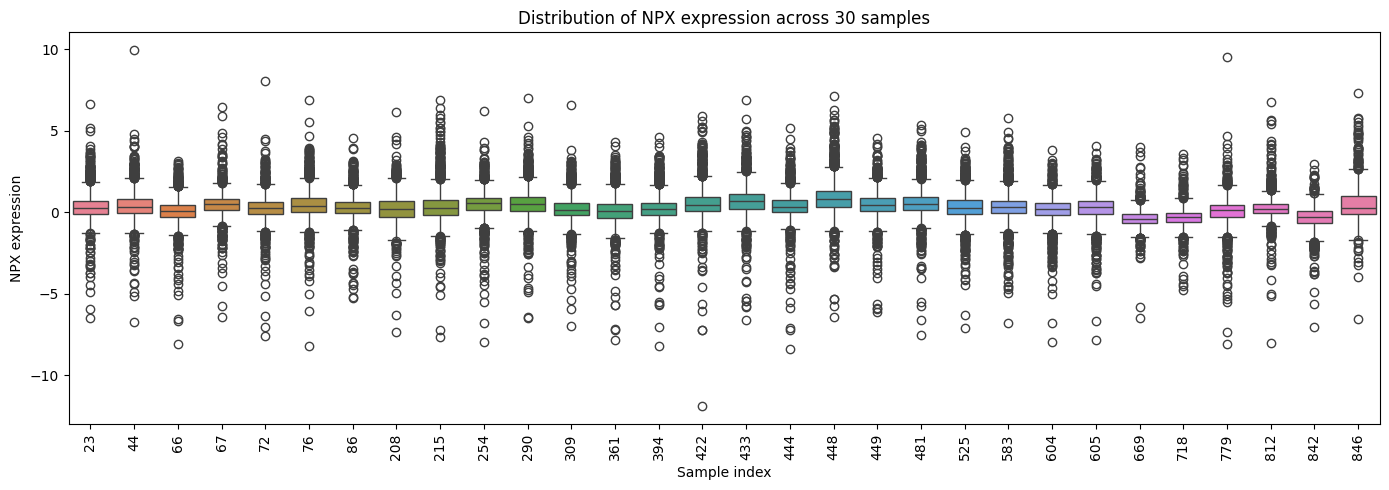

In [18]:
# === PROTEIN EXPRESSION DISTRIBUTION ===

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Select only protein expression values
protein_data = proteins.drop(columns=["sample_kit_id"])

# Randomly select 30 samples for visualization
selected_samples = protein_data.sample(
    n=30,
    random_state=42
)

# Create boxplots
plt.figure(figsize=(14, 5))

sns.boxplot(
    data=selected_samples.T
)

plt.xlabel("Sample index")
plt.ylabel("NPX expression")
plt.title("Distribution of NPX expression across 30 samples")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


**NPX expression distribution across samples**

The distribution of NPX protein expression values was explored using boxplots for a reproducible random subset of 30 samples.

Most samples showed broadly comparable median NPX values and interquartile ranges, suggesting no major differences in the overall expression distributions within the selected subset. Some variation in central tendency and spread was observed, along with several extreme NPX values.

Numerous values outside the boxplot whiskers were observed across samples. However, these values represent expression measurements from different proteins, which naturally exhibit different abundance distributions. Therefore, they should not automatically be interpreted as technical outliers.

Although the boxplots provide an initial overview of sample-level expression distributions, they are insufficient to reliably identify aberrant samples. Further investigation using protein-wise standardization and principal component analysis (PCA) is required. No samples or protein measurements were removed at this stage.

In [22]:
# === OUTLIER DETECTION PER PROTEIN ===

# Select protein expression data
protein_data = proteins.drop(columns=["sample_kit_id"])

# Calculate quartiles for each protein
Q1 = protein_data.quantile(0.25)
Q3 = protein_data.quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Define outlier boundaries per protein
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify potential outliers
outlier_mask = (
    protein_data.lt(lower_bound) |
    protein_data.gt(upper_bound)
)

# Count outliers per protein
outliers_per_protein = outlier_mask.sum()

# Create summary table
outlier_summary = pd.DataFrame({
    "Number of outliers": outliers_per_protein,
    "Outliers (%)": (
        outliers_per_protein /
        protein_data.notna().sum() * 100
    ).round(2)
})

# Sort by number of outliers
outlier_summary = outlier_summary.sort_values(
    "Number of outliers",
    ascending=False
)

print("=== PROTEIN OUTLIER SUMMARY ===")

print("Proteins with at least one potential outlier:",
      (outlier_summary["Number of outliers"] > 0).sum())

print("Total potential outlying NPX measurements:",
      outlier_mask.sum().sum())

display(outlier_summary.head(15))


=== PROTEIN OUTLIER SUMMARY ===
Proteins with at least one potential outlier: 1441
Total potential outlying NPX measurements: 29898


,Number of outliers,Outliers (%)
ITGA6,200,23.07
LTA4H,194,22.38
DPEP2,194,22.38
SMARCA2,174,20.07
FOLR3,145,16.72
TGM2,142,16.38
PKLR,128,14.76
HMBS,128,14.76
RILP,117,13.49
IL13,111,12.80


**Protein-wise outlier detection**

Potential outliers in protein expression were identified separately for each protein using the 1.5 × IQR rule.

Of the 1,481 proteins, 1,441 (97.3%) contained at least one potential outlying NPX measurement. In total, 29,898 protein-sample measurements were flagged as potential outliers.

The highest proportions of outlying measurements were observed for ITGA6 (23.07%), LTA4H (22.38%) and DPEP2 (22.38%).

However, these results do not necessarily indicate technical errors. The IQR method identifies statistically extreme observations, which may arise from biological heterogeneity, skewed protein expression distributions or technical variation between batches.

Therefore, no protein measurements were removed based solely on the IQR results. Further investigation of sample-level outlier patterns and potential technical factors is required.

In [23]:
# === OUTLIER COUNT PER SAMPLE ===

# Count potential outlying proteins per sample
outliers_per_sample = outlier_mask.sum(axis=1)

# Calculate percentage of outliers per sample
valid_proteins_per_sample = protein_data.notna().sum(axis=1)

outlier_percentage = (
    outliers_per_sample / valid_proteins_per_sample * 100
)

# Create summary table
sample_outlier_summary = pd.DataFrame({
    "sample_kit_id": proteins["sample_kit_id"],
    "Number of outlying proteins": outliers_per_sample,
    "Outliers (%)": outlier_percentage.round(2)
})

# Sort by percentage of outliers
sample_outlier_summary = sample_outlier_summary.sort_values(
    "Outliers (%)",
    ascending=False
)

print("=== SAMPLE-LEVEL OUTLIER SUMMARY ===")

display(sample_outlier_summary[
    ["Number of outlying proteins", "Outliers (%)"]
].describe().round(2))

print("\nTop 10 samples with most outlying proteins:")
display(sample_outlier_summary.head(10))


=== SAMPLE-LEVEL OUTLIER SUMMARY ===


,Number of outlying proteins,Outliers (%)
count,867.00,867.00
mean,34.48,2.35
std,36.81,2.51
min,3.00,0.20
25%,13.00,0.89
50%,23.00,1.56
75%,42.00,2.85
max,346.00,23.51



Top 10 samples with most outlying proteins:


,sample_kit_id,Number of outlying proteins,Outliers (%)
191,KT00397,346,23.51
479,KT01598,293,19.90
100,KT00280,281,19.12
662,KT02473,271,18.41
435,KT01553,259,17.60
69,KT00165,244,16.63
436,KT01554,231,15.69
838,KT03899,199,13.66
182,KT00388,170,11.55
841,KT03902,165,11.32


**Sample-level outlier detection**

To identify samples with unusually high numbers of extreme protein expression values, the number and percentage of protein-wise IQR outliers were calculated for each sample.

The median number of outlying proteins per sample was 23 (1.56%), while the mean was 34.48 (2.35%). The distribution was right-skewed, with a small number of samples showing substantially higher outlier counts.

The most extreme sample, KT00397, contained 346 outlying protein measurements (23.51%), followed by KT01598 (293; 19.90%) and KT00280 (281; 19.12%).

These samples were flagged for further investigation. However, a high proportion of statistically extreme protein measurements does not necessarily indicate poor sample quality, as the observed differences may reflect biological heterogeneity, technical batch effects or differences in protein expression distributions.

No samples were excluded at this stage. Further assessment using principal component analysis (PCA) and sample metadata is required.

## b.	Possible detection of aberrant samples with PCA ##

Proteins included in PCA: 1442
Explained variance PC1: 23.81 %
Explained variance PC2: 8.67 %


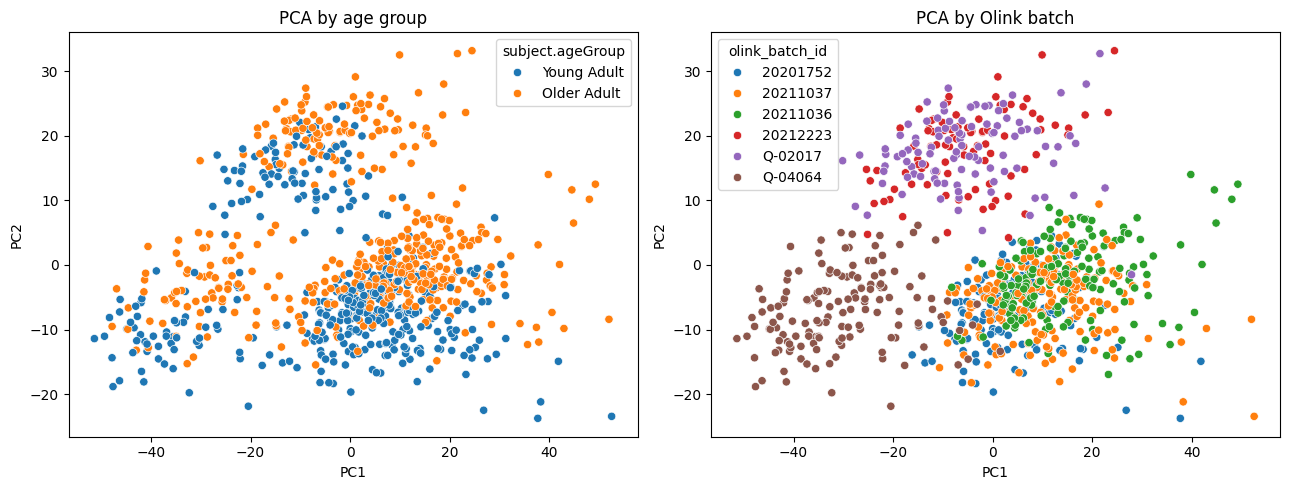

In [25]:
# === PCA FOR SAMPLE-LEVEL OUTLIER DETECTION ===

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Select proteins without missing values
complete_proteins = protein_data.dropna(axis=1)

print("Proteins included in PCA:", complete_proteins.shape[1])

# Standardize each protein
scaler = StandardScaler()
scaled_data = scaler.fit_transform(complete_proteins)

# Perform PCA
pca = PCA(n_components=2)
pca_result = pca.fit_transform(scaled_data)

# Create PCA dataframe
pca_df = pd.DataFrame(
    pca_result,
    columns=["PC1", "PC2"]
)

# Add sample identifiers
pca_df["sample_kit_id"] = proteins["sample_kit_id"].values

# Merge with metadata
pca_df = pca_df.merge(
    metadata[
        ["sample_kit_id", "subject.ageGroup",
         "olink_batch_id", "subject.subjectGuid"]
    ],
    on="sample_kit_id",
    validate="one_to_one"
)

# Explained variance
print("Explained variance PC1:",
      round(pca.explained_variance_ratio_[0] * 100, 2), "%")

print("Explained variance PC2:",
      round(pca.explained_variance_ratio_[1] * 100, 2), "%")

# Plot PCA by age group and batch
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="subject.ageGroup",
    ax=axes[0]
)
axes[0].set_title("PCA by age group")

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="olink_batch_id",
    ax=axes[1]
)
axes[1].set_title("PCA by Olink batch")

plt.tight_layout()
plt.show()


**Principal component analysis (PCA)**

Principal component analysis was performed on 1,442 proteins without missing NPX values. Protein expression values were standardized prior to PCA to prevent proteins with higher variance from dominating the analysis.

The first two principal components explained 23.81% and 8.67% of the total variance, respectively, accounting for 32.48% combined.

When samples were coloured according to age group, partial separation was observed, particularly along PC2. However, substantial overlap remained between Young Adults and Older Adults.

More pronounced clustering was observed when samples were coloured according to Olink batch. In particular, batch Q-04064 formed a distinct cluster with strongly negative PC1 scores, while batches Q-02017 and 20212223 were predominantly located at higher PC2 scores.

These findings suggest that batch-associated variation contributes substantially to the observed differences in global protein expression profiles. However, PCA alone cannot establish whether these differences are technical or reflect differences in sample composition.

No samples or batches were excluded based on the PCA results. Further investigation is required to distinguish individual aberrant samples from systematic batch-associated variation.

This PCA was performed as an exploratory quality-control analysis on the unfiltered NPX dataset. Since missing-value handling, feature filtering and possible batch correction had not yet been completed, the PCA results should be reassessed after the final preprocessing steps.

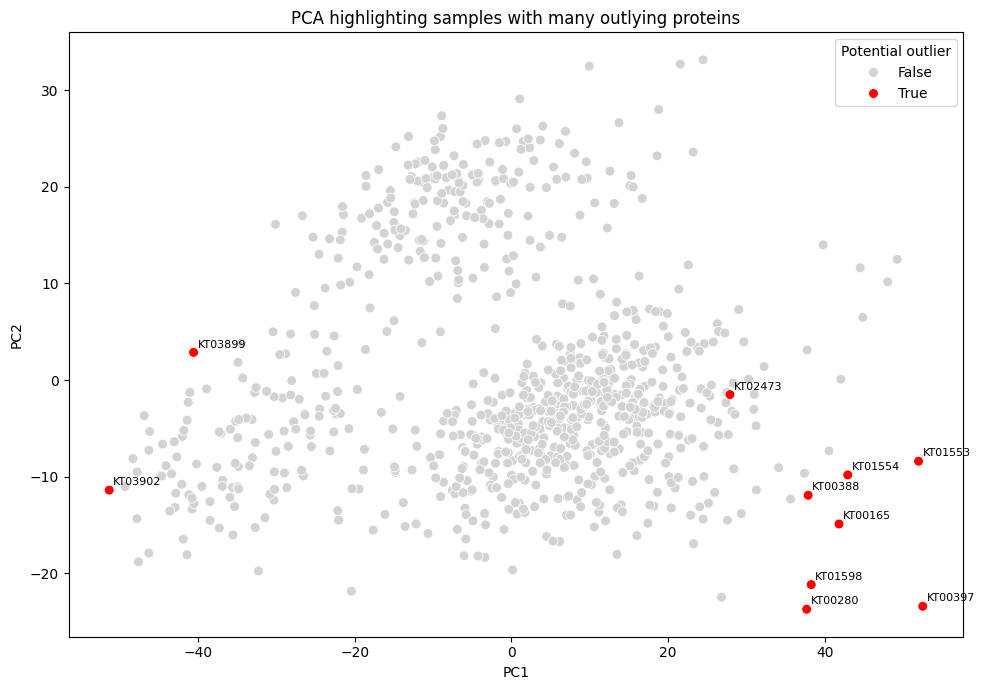

In [26]:
# === HIGHLIGHT POTENTIAL OUTLIER SAMPLES IN PCA ===

# Select top 10 samples with most outlying proteins
top_outliers = sample_outlier_summary.head(10)[
    "sample_kit_id"
].tolist()

# Mark these samples in the PCA dataframe
pca_df["Potential outlier"] = pca_df[
    "sample_kit_id"
].isin(top_outliers)

# Plot
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Potential outlier",
    palette={False: "lightgrey", True: "red"},
    s=50
)

# Add sample labels
for _, row in pca_df[pca_df["Potential outlier"]].iterrows():
    plt.text(
        row["PC1"] + 0.5,
        row["PC2"] + 0.5,
        row["sample_kit_id"],
        fontsize=8
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA highlighting samples with many outlying proteins")

plt.tight_layout()
plt.show()


**Identification of potential aberrant samples using PCA**

The ten samples with the highest proportions of protein-wise IQR outliers were highlighted in the PCA plot to investigate whether these samples also exhibited unusual global protein expression profiles.

Several selected samples, including KT00397, KT00280 and KT01598, were located at the periphery of the PCA distribution, with high PC1 scores and strongly negative PC2 scores. Other samples, such as KT03899 and KT03902, were positioned towards the left side of the PCA, whereas KT02473 was located closer to the central sample distribution.

These findings indicate that several samples with high numbers of outlying protein measurements also exhibit unusual multivariate expression profiles. However, the selected samples did not form a single distinct cluster.

An extreme PCA position alone does not demonstrate a technical error, since differences in protein expression may also reflect biological variation or batch-associated effects. Therefore, these samples were retained for further investigation of potential technical and biological explanations.

## c.	Check if reason for outliers is technical or biological explainable ##

In [27]:
# === INVESTIGATE POTENTIAL OUTLIER SAMPLES ===

# Select top 10 samples based on outlying proteins
top_outliers = sample_outlier_summary.head(10)[
    "sample_kit_id"
].tolist()

# Select relevant metadata
columns_to_check = [
    "sample_kit_id",
    "subject.subjectGuid",
    "subject.ageGroup",
    "subject.biologicalSex",
    "infl.hs_crp",
    "olink_batch_id",
    "olink_plate_id",
    "sample.visitName",
    "pct_below_lod",
    "n_missing_npx"
]

# Extract metadata of selected samples
outlier_metadata = metadata[
    metadata["sample_kit_id"].isin(top_outliers)
][columns_to_check].copy()

# Merge with the outlier percentages
outlier_metadata = outlier_metadata.merge(
    sample_outlier_summary[
        ["sample_kit_id",
         "Number of outlying proteins",
         "Outliers (%)"]
    ],
    on="sample_kit_id",
    validate="one_to_one"
)

# Sort by outlier percentage
outlier_metadata = outlier_metadata.sort_values(
    "Outliers (%)",
    ascending=False
)

display(outlier_metadata)


,sample_kit_id,subject.subjectGuid,subject.ageGroup,subject.biologicalSex,infl.hs_crp,olink_batch_id,olink_plate_id,sample.visitName,pct_below_lod,n_missing_npx,Number of outlying proteins,Outliers (%)
3,KT00397,BR1018,Young Adult,Male,0.8,20211037,20211037_SS210109,Flu Year 1 Day 90,6.7,0,346,23.51
6,KT01598,BR1007,Young Adult,Male,1.2,20211037,20211037_SS210111,Immune Variation Day 0,8.2,0,293,19.90
1,KT00280,BR1032,Young Adult,Male,0.3,20201752,20201752_SS200050_NEURO_ONC,Immune Variation Day 90,5.2,2,281,19.12
7,KT02473,BR1043,Young Adult,Male,0.6,Q-02017,Q-02017_SS220400,Flu Year 2 Day 0,5.2,0,271,18.41
4,KT01553,BR2003,Older Adult,Male,0.3,20211037,20211037_SS210120,Immune Variation Day 7,7.2,0,259,17.60
0,KT00165,BR1016,Young Adult,Male,2.6,20201752,20201752_SS200051_NEU_ONC,Immune Variation Day 7,5.7,5,244,16.63
5,KT01554,BR2024,Older Adult,Female,0.6,20211037,20211037_SS210120,Immune Variation Day 0,7.1,0,231,15.69
8,KT03899,BR2032,Older Adult,Female,10.0,Q-04064,Q-04064_SS220987,Flu Year 3 Stand-Alone,11.1,0,199,13.66
2,KT00388,BR2016,Older Adult,Female,1.6,20211037,20211037_SS210111,Flu Year 1 Day 0,6.5,0,170,11.55
9,KT03902,BR1040,Young Adult,Male,0.3,Q-04064,Q-04064_SS220992,Flu Year 3 Stand-Alone,10.6,0,165,11.32


**Investigation of technical and biological factors**

Metadata from the ten samples with the highest proportions of outlying protein measurements were examined to investigate potential technical and biological explanations.

Most selected samples contained no missing NPX values, and their percentages of measurements below the limit of detection ranged from 5.2% to 11.1%. Therefore, the observed expression abnormalities could not be readily explained by high levels of missingness.

The samples originated from both age groups and several Olink batches. Five of the ten samples belonged to batch 20211037, while two samples (KT01553 and KT01554) were measured on the same Olink plate. This suggests that potential batch- or plate-associated effects warrant further investigation.

Most selected samples exhibited relatively low hs-CRP concentrations, although KT03899 had a value of 10.0, potentially indicating an inflammatory contribution to its expression profile.

No definitive technical or biological explanation could be established from the available metadata. Therefore, the selected samples were retained pending further investigation of donor- and plate-associated patterns.

In [28]:
# === DONOR AND PLATE INVESTIGATION ===

# Add outlier percentages to the metadata
qc_data = metadata.merge(
    sample_outlier_summary[
        ["sample_kit_id", "Outliers (%)"]
    ],
    on="sample_kit_id",
    validate="one_to_one"
)

# Select donors belonging to the top 10 outlier samples
selected_donors = outlier_metadata[
    "subject.subjectGuid"
].unique()

# Compare samples from the same donors
donor_comparison = qc_data[
    qc_data["subject.subjectGuid"].isin(selected_donors)
].groupby("subject.subjectGuid")["Outliers (%)"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

print("=== OUTLIER PERCENTAGES BY DONOR ===")
display(donor_comparison)

# Select plates containing the top 10 outlier samples
selected_plates = outlier_metadata[
    "olink_plate_id"
].unique()

# Compare samples from the same plates
plate_comparison = qc_data[
    qc_data["olink_plate_id"].isin(selected_plates)
].groupby("olink_plate_id")["Outliers (%)"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

print("\n=== OUTLIER PERCENTAGES BY OLINK PLATE ===")
display(plate_comparison)


=== OUTLIER PERCENTAGES BY DONOR ===


,count,mean,median,min,max
subject.subjectGuid,,,,,
BR1007,10,3.17,0.98,0.55,19.90
BR1016,10,3.39,2.04,0.61,16.63
BR1018,10,4.52,2.31,0.82,23.51
BR1032,10,6.20,5.70,1.29,19.12
BR1040,10,2.12,1.22,0.20,11.32
BR1043,10,3.16,1.23,0.41,18.41
BR2003,10,2.70,0.51,0.34,17.60
BR2016,10,4.86,3.46,2.38,11.55
BR2024,10,3.26,1.87,0.75,15.69



=== OUTLIER PERCENTAGES BY OLINK PLATE ===


,count,mean,median,min,max
olink_plate_id,,,,,
20201752_SS200050_NEURO_ONC,44,1.56,0.82,0.27,19.12
20201752_SS200051_NEU_ONC,39,1.20,0.68,0.34,16.63
20211037_SS210109,48,1.77,1.22,0.41,23.51
20211037_SS210111,51,1.86,0.95,0.41,19.90
20211037_SS210120,47,1.62,0.82,0.34,17.60
Q-02017_SS220400,26,3.55,2.11,1.02,18.41
Q-04064_SS220987,25,5.87,5.35,2.54,13.66
Q-04064_SS220992,11,5.10,3.91,2.61,11.32


**Donor- and plate-associated outlier patterns**

To investigate potential technical and biological explanations for the identified outliers, the proportion of outlying protein measurements was compared across samples from the same donors and Olink plates.

Considerable within-donor variability was observed. For example, donor BR1018 had a median outlier percentage of 2.31%, whereas the maximum reached 23.51%. Similar patterns were observed for several other donors, suggesting that certain deviations may be specific to individual samples or sampling time points rather than representing stable donor-associated expression profiles.

At the plate level, most selected Olink plates showed relatively low median outlier percentages (0.68–2.11%). However, two plates from batch Q-04064 exhibited higher median percentages (5.35% and 3.91%). This observation is consistent with the previously observed separation of batch Q-04064 in the PCA and suggests that systematic batch-associated variation may contribute to the detected outliers.

Nevertheless, protein-wise IQR thresholds were calculated across all batches, meaning that systematic differences between batches may increase the number of flagged values. The observed patterns therefore do not establish technical measurement errors.

Overall, the results suggest a combination of sample-specific and batch-associated variation. No samples or plates were excluded at this stage.

In [29]:
# === WITHIN-BATCH OUTLIER DETECTION ===

# Combine protein expression with batch information
batch_proteins = proteins.merge(
    metadata[["sample_kit_id", "olink_batch_id"]],
    on="sample_kit_id",
    validate="one_to_one"
)

# Store outlier percentages for each sample
within_batch_results = []

# Calculate outlier boundaries separately per batch
for batch, group in batch_proteins.groupby("olink_batch_id"):

    # Select protein expression columns
    group_proteins = group[protein_data.columns]

    # Calculate IQR boundaries within batch
    Q1 = group_proteins.quantile(0.25)
    Q3 = group_proteins.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    # Identify outliers
    outliers = (
        group_proteins.lt(lower) |
        group_proteins.gt(upper)
    )

    # Calculate percentage per sample
    percentage = (
        outliers.sum(axis=1) /
        group_proteins.notna().sum(axis=1) * 100
    )

    # Store results
    result = pd.DataFrame({
        "sample_kit_id": group["sample_kit_id"],
        "olink_batch_id": batch,
        "Within-batch outliers (%)": percentage
    })

    within_batch_results.append(result)

# Combine results from all batches
within_batch_summary = pd.concat(
    within_batch_results,
    ignore_index=True
)

# Compare global and within-batch outliers
comparison = sample_outlier_summary.merge(
    within_batch_summary,
    on="sample_kit_id",
    validate="one_to_one"
)

print("=== GLOBAL VS WITHIN-BATCH OUTLIERS ===")

display(
    comparison[
        ["Outliers (%)", "Within-batch outliers (%)"]
    ].describe().round(2)
)

# Show the original top 10 samples
display(
    comparison[
        comparison["sample_kit_id"].isin(top_outliers)
    ].sort_values("Outliers (%)", ascending=False)
)


=== GLOBAL VS WITHIN-BATCH OUTLIERS ===


,Outliers (%),Within-batch outliers (%)
count,867.00,867.00
mean,2.35,2.58
std,2.51,2.68
min,0.20,0.41
25%,0.89,1.30
50%,1.56,1.83
75%,2.85,2.85
max,23.51,27.38


,sample_kit_id,Number of outlying proteins,Outliers (%),olink_batch_id,Within-batch outliers (%)
0,KT00397,346,23.51,20211037,27.377717
1,KT01598,293,19.90,20211037,22.622283
2,KT00280,281,19.12,20201752,26.258503
3,KT02473,271,18.41,Q-02017,21.942935
4,KT01553,259,17.60,20211037,20.244565
5,KT00165,244,16.63,20201752,23.858214
6,KT01554,231,15.69,20211037,18.817935
7,KT03899,199,13.66,Q-04064,6.451613
8,KT00388,170,11.55,20211037,14.605978
9,KT03902,165,11.32,Q-04064,2.402196


**Global versus within-batch outlier detection**

To distinguish potential sample-specific abnormalities from systematic batch-associated differences, protein-wise IQR outlier detection was repeated separately within each Olink batch.

The overall median percentage of outlying protein measurements was 1.56% using global IQR thresholds and 1.83% using batch-specific thresholds.

Most of the previously identified candidate samples continued to exhibit high proportions of outlying protein measurements within their respective batches. For example, KT00397 increased from 23.51% to 27.38%, while KT00280 increased from 19.12% to 26.26%. This suggests that their unusual expression profiles cannot be explained solely by differences between Olink batches.

In contrast, KT03899 and KT03902, both belonging to batch Q-04064, showed substantially lower within-batch outlier percentages (6.45% and 2.40%, respectively) compared with their global percentages (13.66% and 11.32%). This suggests that systematic batch-associated differences may contribute to their apparent global outlier status.

However, batch-specific IQR thresholds differ from global thresholds and are estimated from smaller sample groups. Therefore, the percentages are exploratory indicators rather than direct measures of technical variation.

Overall, the results indicate both sample-specific and batch-associated patterns of variation. No samples were excluded at this stage, since technical measurement errors could not be established from the available information.

## d.	Decide if outliers should be removed or not ##

In [30]:
# === CORRECTING INVALID BMI AND WEIGHT VALUES ===

import numpy as np
import pandas as pd

# Create a copy of the original metadata
metadata_clean = metadata.copy()

# Count invalid values before correction
print("=== BEFORE CORRECTION ===")
print("BMI values equal to zero:",
      (metadata_clean["am.bmi"] == 0).sum())

print("Weight values equal to zero:",
      (metadata_clean["am.weight"] == 0).sum())

# Replace physiologically impossible values with NaN
metadata_clean.loc[
    metadata_clean["am.bmi"] == 0, "am.bmi"
] = np.nan

metadata_clean.loc[
    metadata_clean["am.weight"] == 0, "am.weight"
] = np.nan

# Check results after correction
print("\n=== AFTER CORRECTION ===")
print("BMI values equal to zero:",
      (metadata_clean["am.bmi"] == 0).sum())

print("Weight values equal to zero:",
      (metadata_clean["am.weight"] == 0).sum())

print("\nMissing BMI values:",
      metadata_clean["am.bmi"].isna().sum())

print("Missing weight values:",
      metadata_clean["am.weight"].isna().sum())

# Verify that all samples were retained
print("\nNumber of samples before:", len(metadata))
print("Number of samples after:", len(metadata_clean))


=== BEFORE CORRECTION ===
BMI values equal to zero: 2
Weight values equal to zero: 6

=== AFTER CORRECTION ===
BMI values equal to zero: 0
Weight values equal to zero: 0

Missing BMI values: 187
Missing weight values: 43

Number of samples before: 867
Number of samples after: 867


**Correction of invalid BMI and body weight measurements**

During data quality control, two BMI measurements and six body weight measurements were identified with a recorded value of zero. Since these values are physiologically impossible in living adults, they were considered invalid and replaced with `NaN`.

Following correction, the number of missing BMI values increased from 185 to 187, while missing body weight values increased from 37 to 43.

The corrections were performed on a copy of the original metadata, preserving the unmodified dataset. All 867 samples were retained to avoid unnecessary loss of valid protein expression, hs-CRP and other clinical measurements.

No imputation was performed at this stage.

**Final outlier decisions**

Potential outliers in hs-CRP and NPX protein expression were identified using the 1.5 × IQR rule. Further investigation included PCA, sample-level outlier counts, donor comparisons and batch-specific analyses.

Although several samples exhibited unusually high numbers of outlying protein measurements, no definitive evidence of technical measurement errors was identified. Some abnormalities appeared to be associated with Olink batch, while others persisted within batches and may reflect sample-specific biological or technical variation.

Therefore, all potential hs-CRP and NPX outliers were retained at this stage. Only physiologically impossible BMI and body weight values were corrected to missing values (`NaN`).

This conservative approach avoids removing potentially meaningful biological variation without sufficient justification.

=== hs-CRP DATA CHECK ===
Minimum hs-CRP: 0.3
Missing values: 16
Values <= 0: 0

=== SKEWNESS COMPARISON ===
Raw hs-CRP: 2.89
Log10 hs-CRP: 0.67


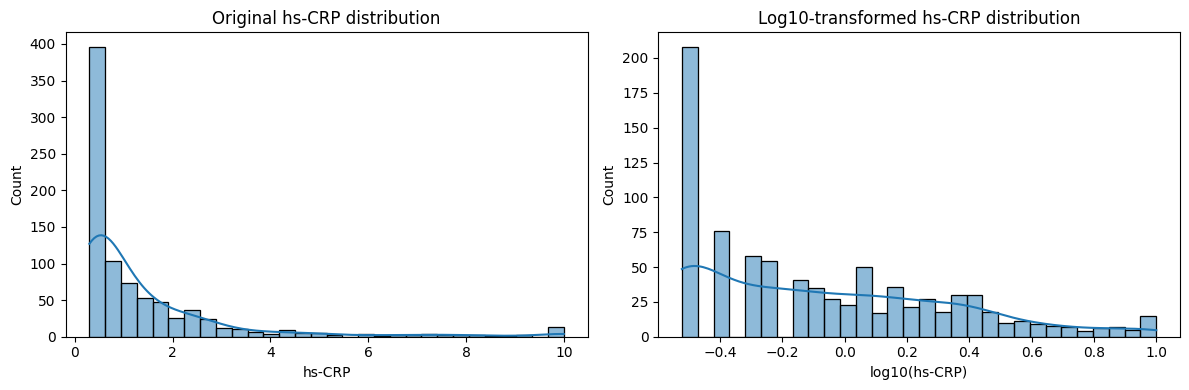

In [31]:
# === LOG-TRANSFORMATION OF hs-CRP ===

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew

# Select original hs-CRP values
crp = metadata_clean["infl.hs_crp"]

# Check if all available values are positive
print("=== hs-CRP DATA CHECK ===")
print("Minimum hs-CRP:", crp.min())
print("Missing values:", crp.isna().sum())
print("Values <= 0:", (crp <= 0).sum())

# Create a new log10-transformed variable
metadata_clean["log_crp"] = np.log10(crp)

# Compare skewness before and after transformation
raw_skew = skew(crp.dropna())
log_skew = skew(metadata_clean["log_crp"].dropna())

print("\n=== SKEWNESS COMPARISON ===")
print("Raw hs-CRP:", round(raw_skew, 2))
print("Log10 hs-CRP:", round(log_skew, 2))

# Compare distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    crp.dropna(),
    bins=30,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Original hs-CRP distribution")
axes[0].set_xlabel("hs-CRP")

sns.histplot(
    metadata_clean["log_crp"].dropna(),
    bins=30,
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Log10-transformed hs-CRP distribution")
axes[1].set_xlabel("log10(hs-CRP)")

plt.tight_layout()
plt.show()


In [32]:
# === CHECK POSSIBLE hs-CRP REPORTING LIMITS ===

print("=== hs-CRP BOUNDARY VALUES ===")

print("Values equal to 0.3:",
      (crp == 0.3).sum())

print("Values equal to 10.0:",
      (crp == 10.0).sum())

print("Percentage at 0.3:",
      round((crp == 0.3).sum() / crp.notna().sum() * 100, 2))

print("Percentage at 10.0:",
      round((crp == 10.0).sum() / crp.notna().sum() * 100, 2))


=== hs-CRP BOUNDARY VALUES ===
Values equal to 0.3: 208
Values equal to 10.0: 13
Percentage at 0.3: 24.44
Percentage at 10.0: 1.53


**Log10-transformation of hs-CRP**

The original hs-CRP distribution was strongly right-skewed (skewness = 2.89). To reduce this asymmetry, hs-CRP concentrations were log10-transformed while preserving the original values in a separate variable.

Following transformation, skewness decreased to 0.67, indicating a substantially more symmetric distribution. However, the transformed values remained somewhat right-skewed.

Further inspection revealed that 208 measurements (24.44% of available hs-CRP values) were exactly equal to the minimum reported value of 0.3, while 13 measurements (1.53%) were equal to the maximum reported value of 10.0. These concentrations may reflect lower and upper reporting limits, respectively, although this requires confirmation from the assay documentation.

Potential censoring represents an important limitation, as log-transformation does not recover the underlying concentrations beyond possible reporting limits.

The log10-transformed hs-CRP variable was retained as a candidate outcome for subsequent statistical analyses. No hs-CRP measurements were excluded, and the original concentration values were preserved.

### Final conclusion – Dataset exploration and outlier detection

**Dataset exploration**

The dataset consisted of 867 plasma samples collected from 96 unique donors, with 1,481 measured protein features. No duplicate sample identifiers were detected. However, repeated measurements were present for 95 donors, indicating that observations from the same donor are not statistically independent.

The study population consisted of 49 Young Adults (25–37 years) and 47 Older Adults (55–67 years). The predefined age-group variable was selected as the primary representation of age for subsequent analyses. Relevant biological, clinical and technical variables were identified, including hs-CRP, biological sex, CMV status, Olink batch and visit information.

**Outlier detection**

Potential outliers were investigated using histograms, boxplots, the interquartile range (IQR) method and principal component analysis (PCA).

The hs-CRP distribution was strongly right-skewed, with 72 of 851 available measurements (8.46%) identified as potential outliers. Since elevated hs-CRP concentrations may reflect genuine inflammatory responses, these measurements were retained.

Protein-wise IQR analysis identified 29,898 potentially outlying NPX measurements across 1,441 proteins. Several samples exhibited unusually high proportions of outlying protein measurements, with KT00397 showing the highest percentage (23.51%).

PCA was performed on 1,442 proteins without missing values. The first two principal components explained 32.48% of the total variance. Pronounced clustering according to Olink batch was observed, particularly for batch Q-04064, indicating potential batch-associated variation.

Further investigation revealed that several samples continued to exhibit unusually high proportions of outlying protein measurements within their respective batches, whereas others, particularly KT03899 and KT03902, showed substantially lower outlier percentages when batch-specific IQR thresholds were applied.

These findings suggest that both sample-specific and batch-associated variation contribute to the observed expression patterns. However, no definitive evidence of technical measurement errors was established.

**Preprocessing decisions**

Two BMI values and six body weight values of zero were identified as physiologically impossible and replaced with `NaN`. All 867 samples were retained.

A log10-transformation of hs-CRP reduced skewness from 2.89 to 0.67. The transformed variable (`log_crp`) was added to the cleaned metadata while preserving the original hs-CRP measurements.

A substantial proportion of hs-CRP measurements occurred exactly at the minimum (0.3; n = 208) or maximum (10.0; n = 13) reported values. These observations may indicate reporting limits, although this requires confirmation.

No potential hs-CRP or NPX outliers were removed solely on the basis of statistical outlier criteria.

**Overall conclusion**

The dataset was considered suitable for further preprocessing, provided that missing-value handling, protein detectability, technical batch effects and final feature selection are appropriately addressed.

The outlier analyses identified several observations requiring caution but provided insufficient evidence to justify excluding complete samples or protein measurements. Therefore, a conservative approach was adopted to preserve potentially meaningful biological variation.

The findings from this analysis will be integrated with the missing-value, normalization, standardization and batch-effect assessments before constructing the final dataset for statistical analysis and machine learning.